In [1]:
!pip install catboost xgboost lightgbm gradio

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import re
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
df = pd.read_csv("laptopData.csv")
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.shape

(1303, 12)

In [5]:
df.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   object 
 2   TypeName          1273 non-null   object 
 3   Inches            1273 non-null   object 
 4   ScreenResolution  1273 non-null   object 
 5   Cpu               1273 non-null   object 
 6   Ram               1273 non-null   object 
 7   Memory            1273 non-null   object 
 8   Gpu               1273 non-null   object 
 9   OpSys             1273 non-null   object 
 10  Weight            1273 non-null   object 
 11  Price             1273 non-null   float64
dtypes: float64(2), object(10)
memory usage: 122.3+ KB


In [7]:
df.describe()

,Unnamed: 0,Price
count,1273.000000,1273.000000
mean,652.674784,59955.814073
std,376.493027,37332.251005
min,0.000000,9270.720000
25%,327.000000,31914.720000
50%,652.000000,52161.120000
75%,980.000000,79333.387200
max,1302.000000,324954.720000


In [8]:
df["Price"].describe()

,Price
count,1273.000000
mean,59955.814073
std,37332.251005
min,9270.720000
25%,31914.720000
50%,52161.120000
75%,79333.387200
max,324954.720000


In [9]:
df.isnull().sum()

,0
Unnamed: 0,30
Company,30
TypeName,30
Inches,30
ScreenResolution,30
Cpu,30
Ram,30
Memory,30
Gpu,30
OpSys,30


In [10]:
df.duplicated().sum()

np.int64(29)

In [11]:
df = df.drop(columns="Unnamed: 0")

In [12]:
df = df.drop_duplicates()

In [13]:
df = df.dropna(how="all")

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.replace("?", np.nan)

In [16]:
df.isnull().sum().sort_values(ascending=False).head(20)

,0
Inches,1
Weight,1
Memory,1
TypeName,0
Company,0
Cpu,0
ScreenResolution,0
Ram,0
Gpu,0
OpSys,0


In [17]:
df["Ram"] = df["Ram"].str.replace("GB", "").astype(int)
df["Weight"] = df["Weight"].str.replace("kg", "").astype(float)
df["Inches"] = df["Inches"].astype(float)

In [18]:
print("Rows with Inches > 20:", (df["Inches"] > 20).sum())
df.loc[df["Inches"] > 20, "Inches"] = (df.loc[df["Inches"] > 20, "Inches"] / 2.54).round(1)

Rows with Inches > 20: 9


In [19]:
df["Inches"] = df["Inches"].fillna(df["Inches"].median())
df["Weight"] = df["Weight"].fillna(df["Weight"].median())
df["Memory"] = df["Memory"].fillna(df["Memory"].mode()[0])

In [20]:
df.isnull().sum().sum()

np.int64(0)

In [21]:
df["Touchscreen"] = df["ScreenResolution"].str.contains("Touchscreen").astype(int)
df["IPS"] = df["ScreenResolution"].str.contains("IPS").astype(int)
res = df["ScreenResolution"].str.extract(r"(\d+)x(\d+)").astype(int)
df["X_res"], df["Y_res"] = res[0], res[1]
df["PPI"] = (np.sqrt(df["X_res"] ** 2 + df["Y_res"] ** 2) / df["Inches"]).round(2)

In [22]:
def cpu_brand(cpu):
    if cpu.startswith("Intel Core i7"): return "Intel Core i7"
    if cpu.startswith("Intel Core i5"): return "Intel Core i5"
    if cpu.startswith("Intel Core i3"): return "Intel Core i3"
    if cpu.startswith("Intel"): return "Other Intel"
    return "AMD"

df["Cpu_brand"] = df["Cpu"].apply(cpu_brand)
df["Cpu_GHz"] = df["Cpu"].str.extract(r"(\d+\.?\d*)GHz")[0].astype(float)

In [23]:
def storage_size(mem, kind):
    total = 0.0
    for part in mem.split("+"):
        m = re.match(r"\s*([\d.]+)\s*(TB|GB)\s*(.*)", part)
        size = float(m.group(1)) * (1024 if m.group(2) == "TB" else 1)
        if m.group(3).strip() == kind:
            total += size
    return total

for col, kind in [("SSD", "SSD"), ("HDD", "HDD"), ("Hybrid", "Hybrid"), ("Flash", "Flash Storage")]:
    df[col] = df["Memory"].apply(lambda m: storage_size(m, kind))

In [24]:
df["Gpu_brand"] = df["Gpu"].str.split().str[0].replace({"ARM": "Other"})

In [25]:
def os_group(os_name):
    if "Windows" in os_name: return "Windows"
    if os_name in ("macOS", "Mac OS X"): return "Mac"
    if os_name == "Linux": return "Linux"
    return "Other"        # No OS / Chrome OS / Android

df["OS"] = df["OpSys"].apply(os_group)

df = df.drop(columns=["ScreenResolution", "Cpu", "Memory", "Gpu", "OpSys"])

df.head()


,Company,TypeName,Inches,Ram,Weight,Price,Touchscreen,IPS,X_res,Y_res,PPI,Cpu_brand,Cpu_GHz,SSD,HDD,Hybrid,Flash,Gpu_brand,OS
0,Apple,Ultrabook,13.3,8,1.37,71378.6832,0,1,2560,1600,226.98,Intel Core i5,2.3,128.0,0.0,0.0,0.0,Intel,Mac
1,Apple,Ultrabook,13.3,8,1.34,47895.5232,0,0,1440,900,127.68,Intel Core i5,1.8,0.0,0.0,0.0,128.0,Intel,Mac
2,HP,Notebook,15.6,8,1.86,30636.0000,0,0,1920,1080,141.21,Intel Core i5,2.5,256.0,0.0,0.0,0.0,Intel,Other
3,Apple,Ultrabook,15.4,16,1.83,135195.3360,0,1,2880,1800,220.53,Intel Core i7,2.7,512.0,0.0,0.0,0.0,AMD,Mac
4,Apple,Ultrabook,13.3,8,1.37,96095.8080,0,1,2560,1600,226.98,Intel Core i5,3.1,256.0,0.0,0.0,0.0,Intel,Mac


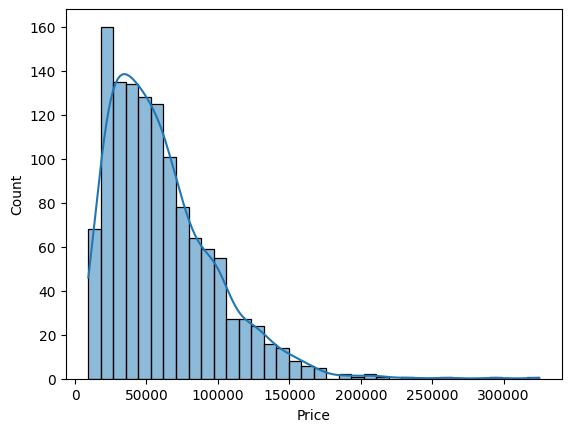

In [26]:
sns.histplot(df["Price"], kde=True)
plt.show()

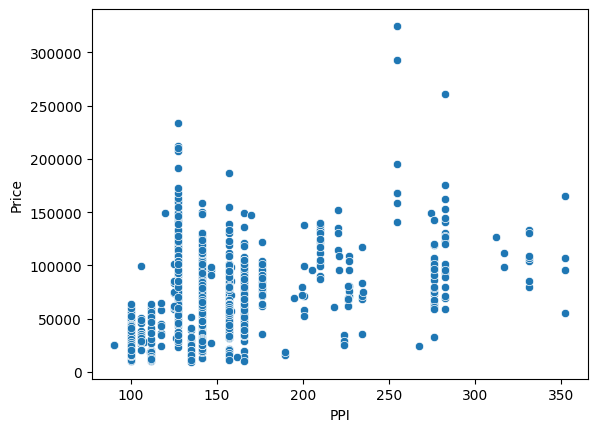

In [27]:
sns.scatterplot(x="PPI", y="Price", data=df)
plt.show()

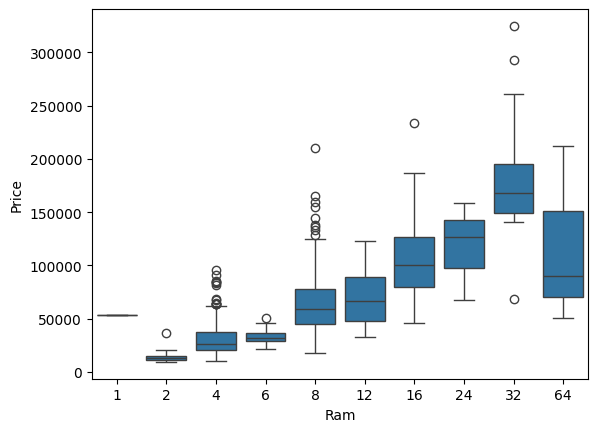

In [28]:
sns.boxplot(x="Ram", y="Price", data=df)
plt.show()

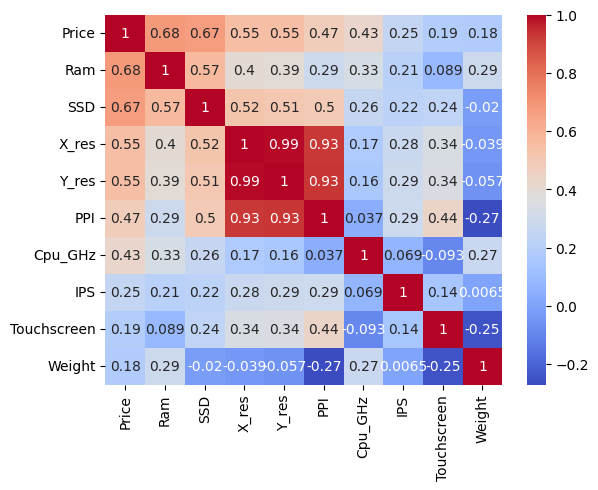

In [29]:
top_cols = df.corr(numeric_only=True)["Price"].abs().sort_values(ascending=False).head(10).index
sns.heatmap(df[top_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

In [30]:
df_clean = df.copy()

In [31]:
high_card = ["Company"]

In [32]:
onehot_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in high_card]
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

In [33]:
X = df.drop(columns="Price")
y = np.log1p(df["Price"])

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()

In [35]:
target_means = {}
for col in high_card:
    target_means[col] = y_train.groupby(X_train[col]).mean()
    X_train[col] = X_train[col].map(target_means[col])
    X_test[col] = X_test[col].map(target_means[col]).fillna(y_train.mean())

In [36]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

In [37]:
skewed = [c for c in num_cols if abs(X_train[c].skew()) > 0.75]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

In [38]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [39]:
y_real = np.expm1(y_test)

In [40]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [41]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

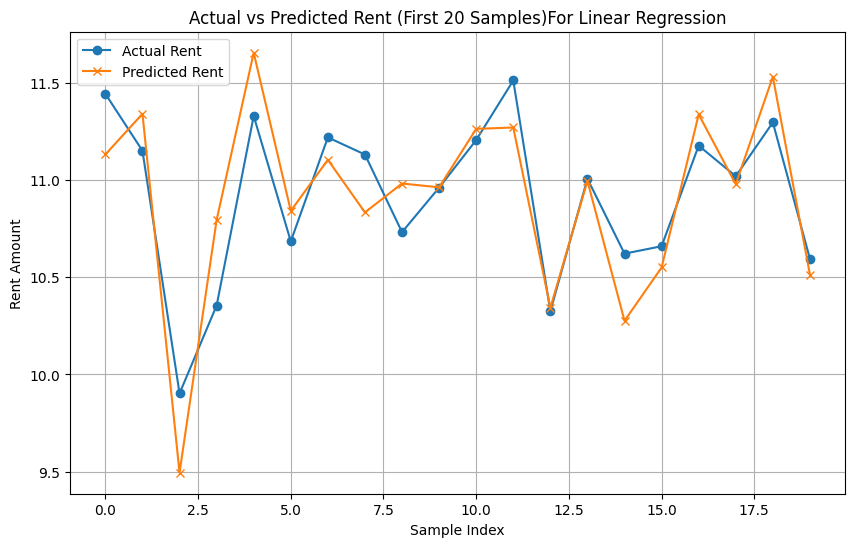

  7%|▋         | 1/15 [00:00<00:03,  3.84it/s]

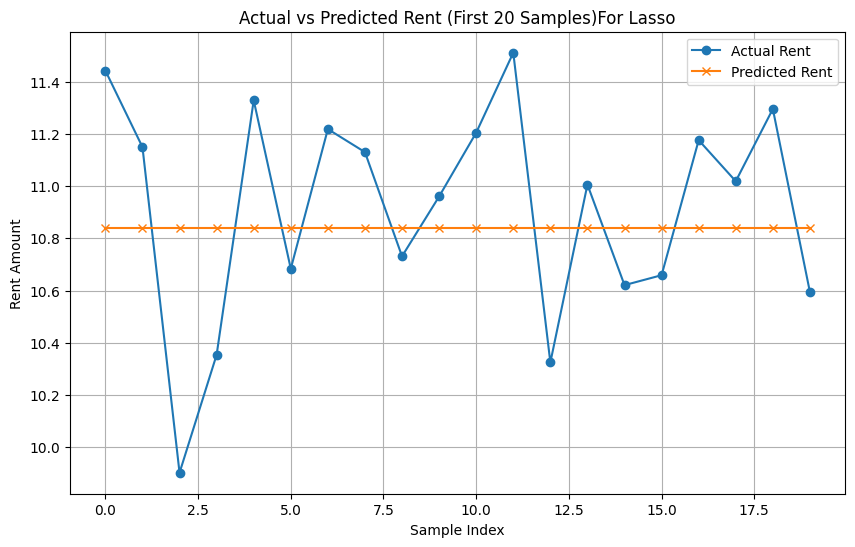

 13%|█▎        | 2/15 [00:00<00:03,  4.17it/s]

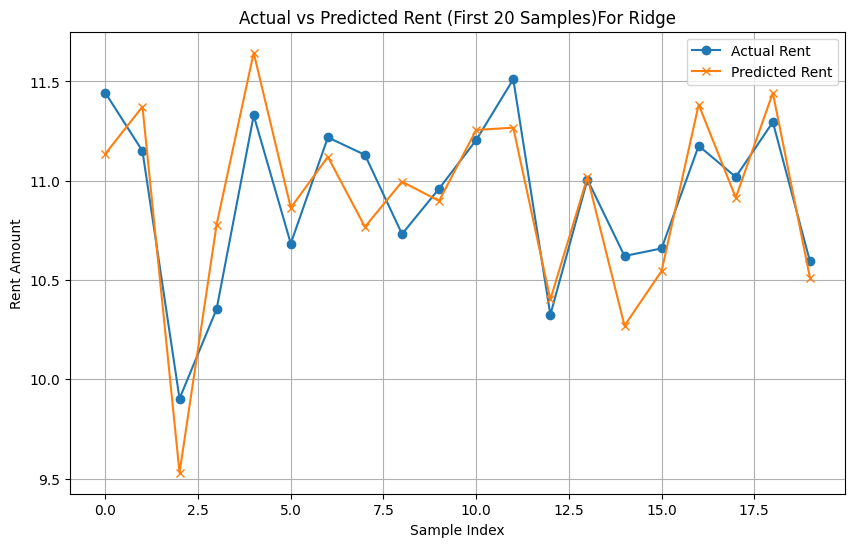

 20%|██        | 3/15 [00:00<00:03,  3.62it/s]

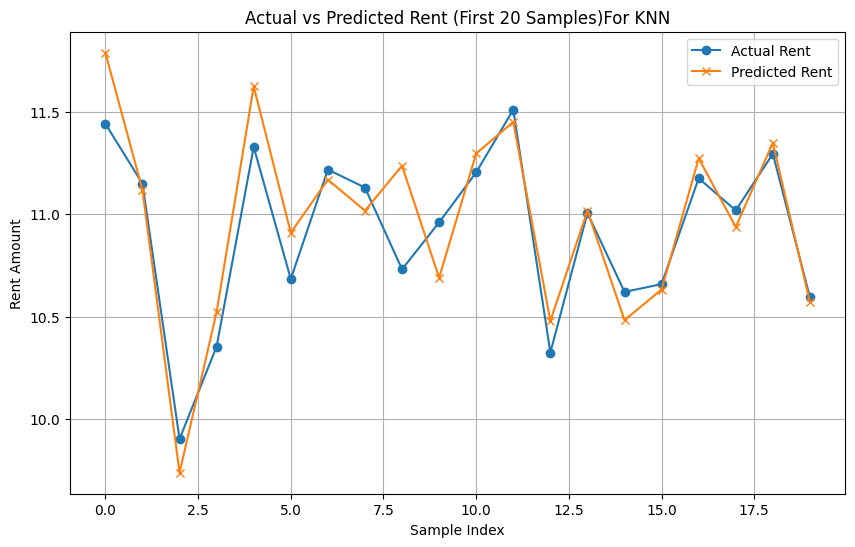

 27%|██▋       | 4/15 [00:01<00:03,  2.91it/s]

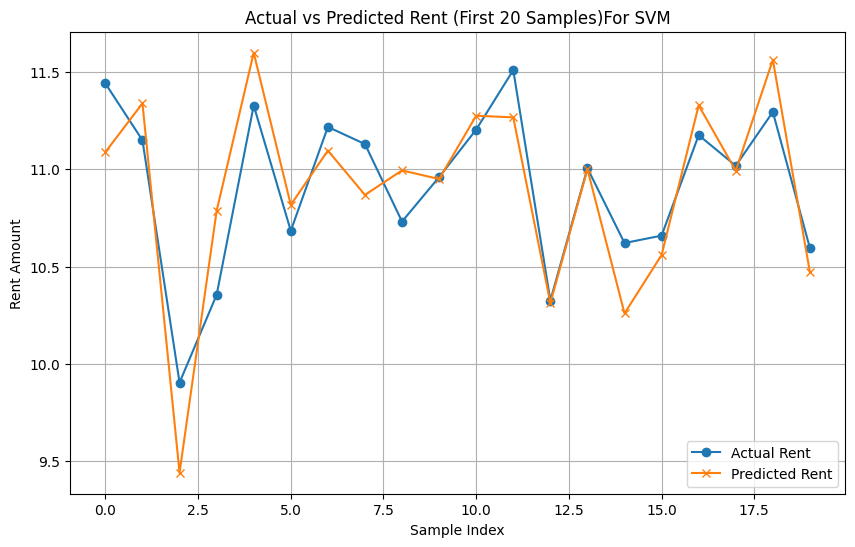

 33%|███▎      | 5/15 [00:33<01:57, 11.73s/it]

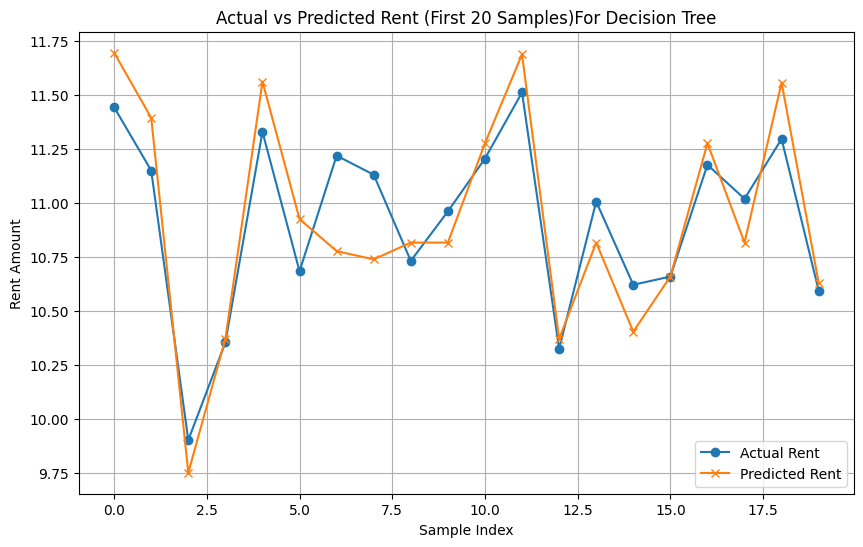

 40%|████      | 6/15 [00:33<01:10,  7.86s/it]

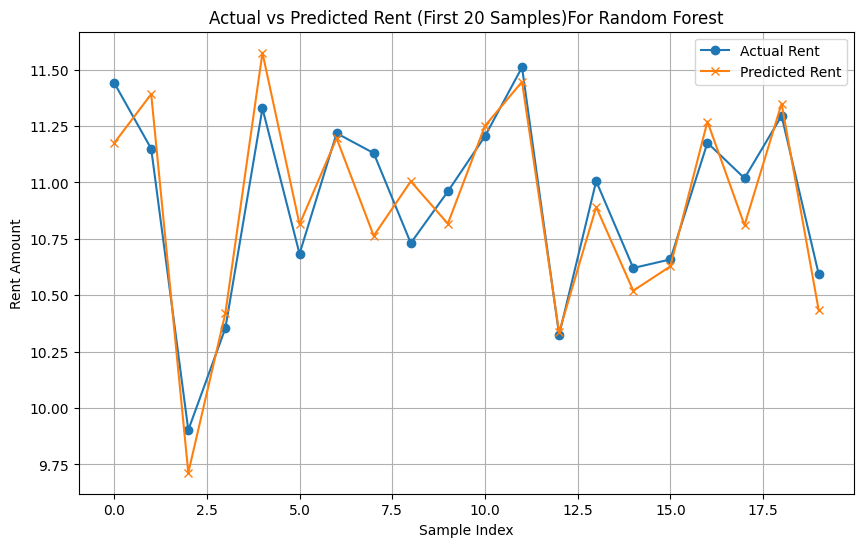

 47%|████▋     | 7/15 [00:34<00:44,  5.55s/it]

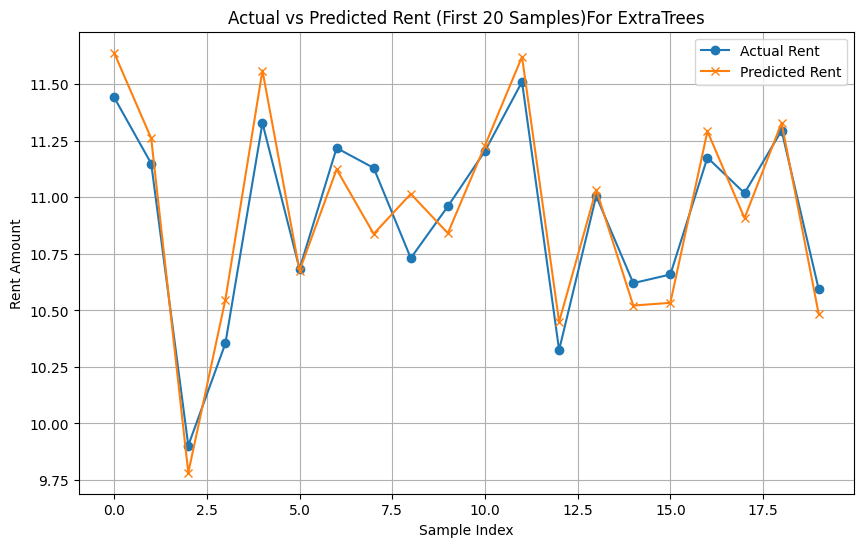

 53%|█████▎    | 8/15 [00:35<00:28,  4.09s/it]

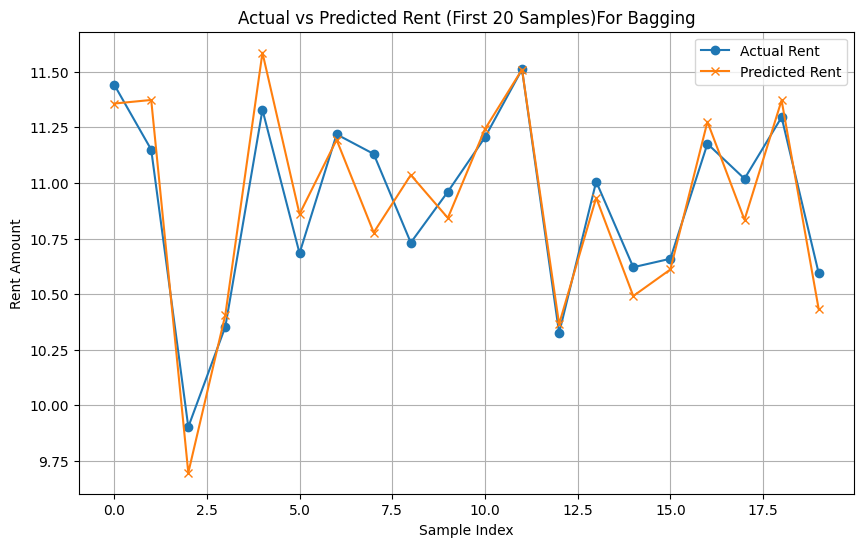

 60%|██████    | 9/15 [00:35<00:17,  2.99s/it]

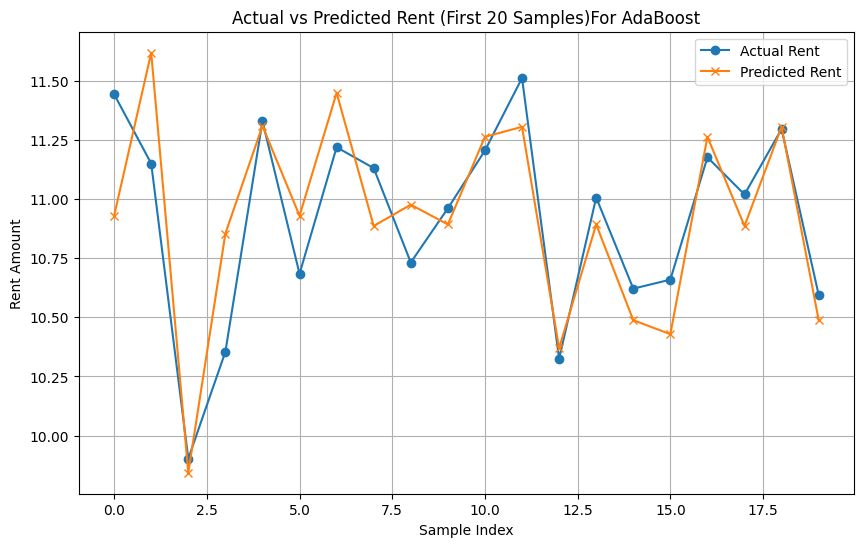

 67%|██████▋   | 10/15 [00:36<00:10,  2.15s/it]

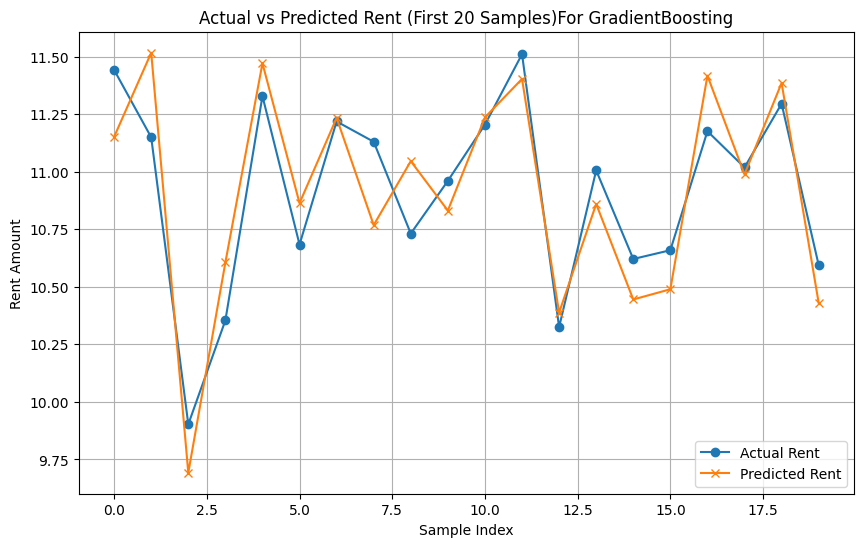

 73%|███████▎  | 11/15 [00:36<00:06,  1.63s/it]

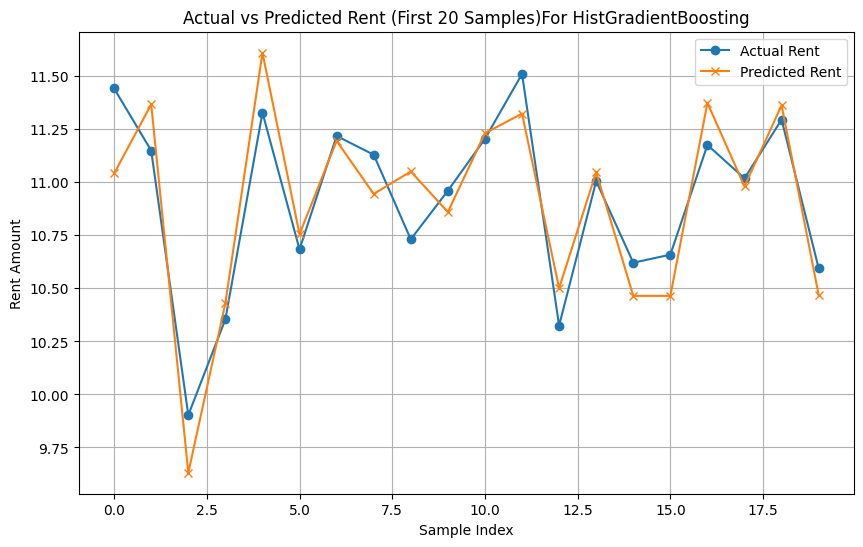

 80%|████████  | 12/15 [00:37<00:03,  1.30s/it]

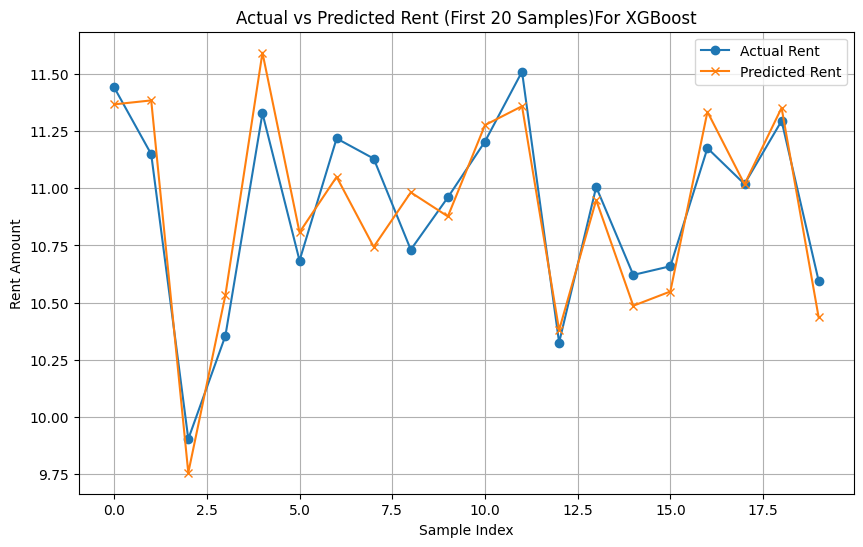

 87%|████████▋ | 13/15 [00:37<00:02,  1.03s/it]

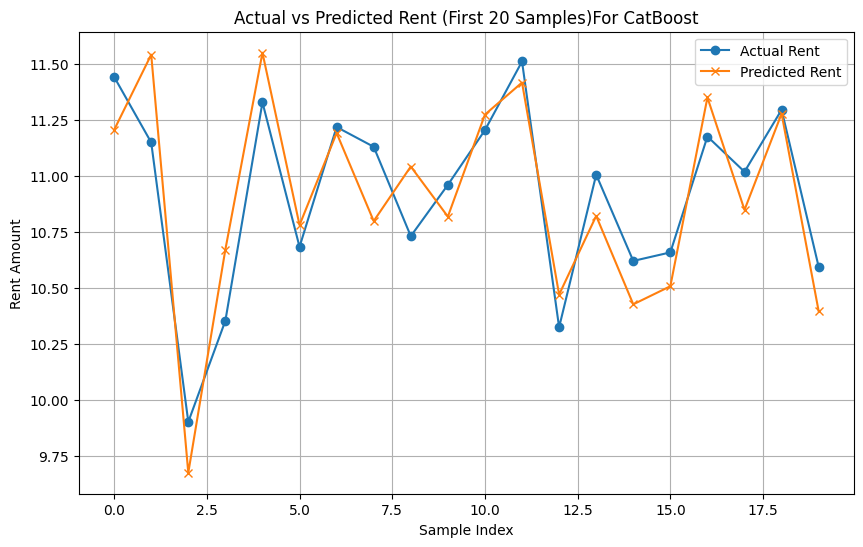

 93%|█████████▎| 14/15 [00:38<00:00,  1.11it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000707 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 276
[LightGBM] [Info] Number of data points in the train set: 995, number of used features: 25
[LightGBM] [Info] Start training from score 10.837873


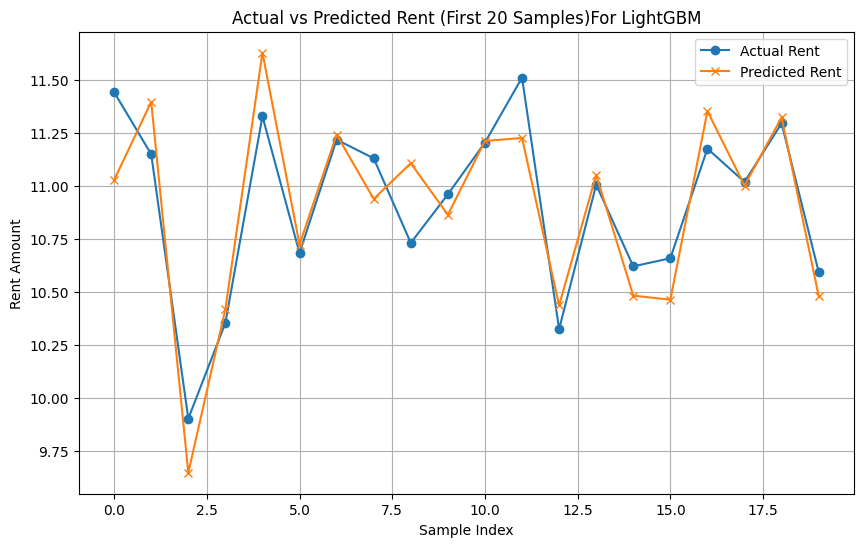

100%|██████████| 15/15 [00:38<00:00,  2.56s/it]


In [42]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [43]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [44]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [45]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [46]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Stacking,0.096114,0.158005,0.018086,0.047515,0.134485,0.217980,0.953591,0.881255
XGBoost,0.075256,0.150133,0.010866,0.042675,0.104239,0.206579,0.972119,0.878966
HistGradientBoosting,0.090350,0.153866,0.013940,0.047095,0.118066,0.217014,0.964231,0.866429
LightGBM,0.090351,0.158005,0.013789,0.047515,0.117427,0.217980,0.964618,0.865238
Random Forest,0.095982,0.162367,0.015731,0.048551,0.125422,0.220344,0.959636,0.862299
Bagging,0.097692,0.167217,0.016145,0.050238,0.127065,0.224138,0.958571,0.857516
CatBoost,0.139388,0.171953,0.031944,0.050748,0.178728,0.225274,0.918034,0.856068
GradientBoosting,0.139967,0.170733,0.032022,0.051304,0.178946,0.226503,0.917833,0.854492
Simple Voting,0.084221,0.158005,0.011232,0.047515,0.105979,0.217980,0.971180,0.854148
Voting,0.084221,0.158005,0.011232,0.047515,0.105979,0.217980,0.971180,0.854148


<Axes: >

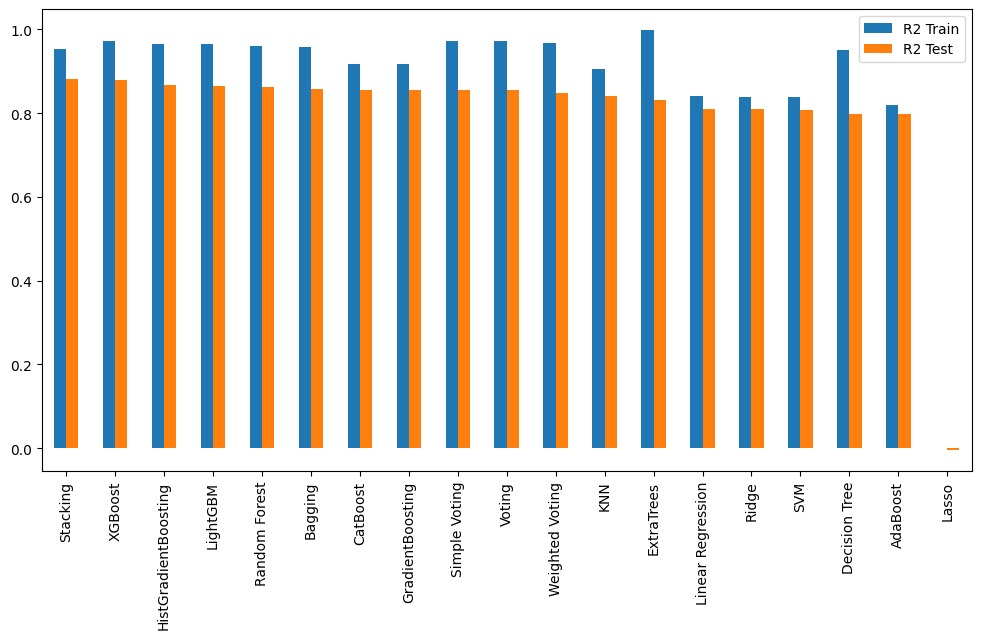

In [47]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

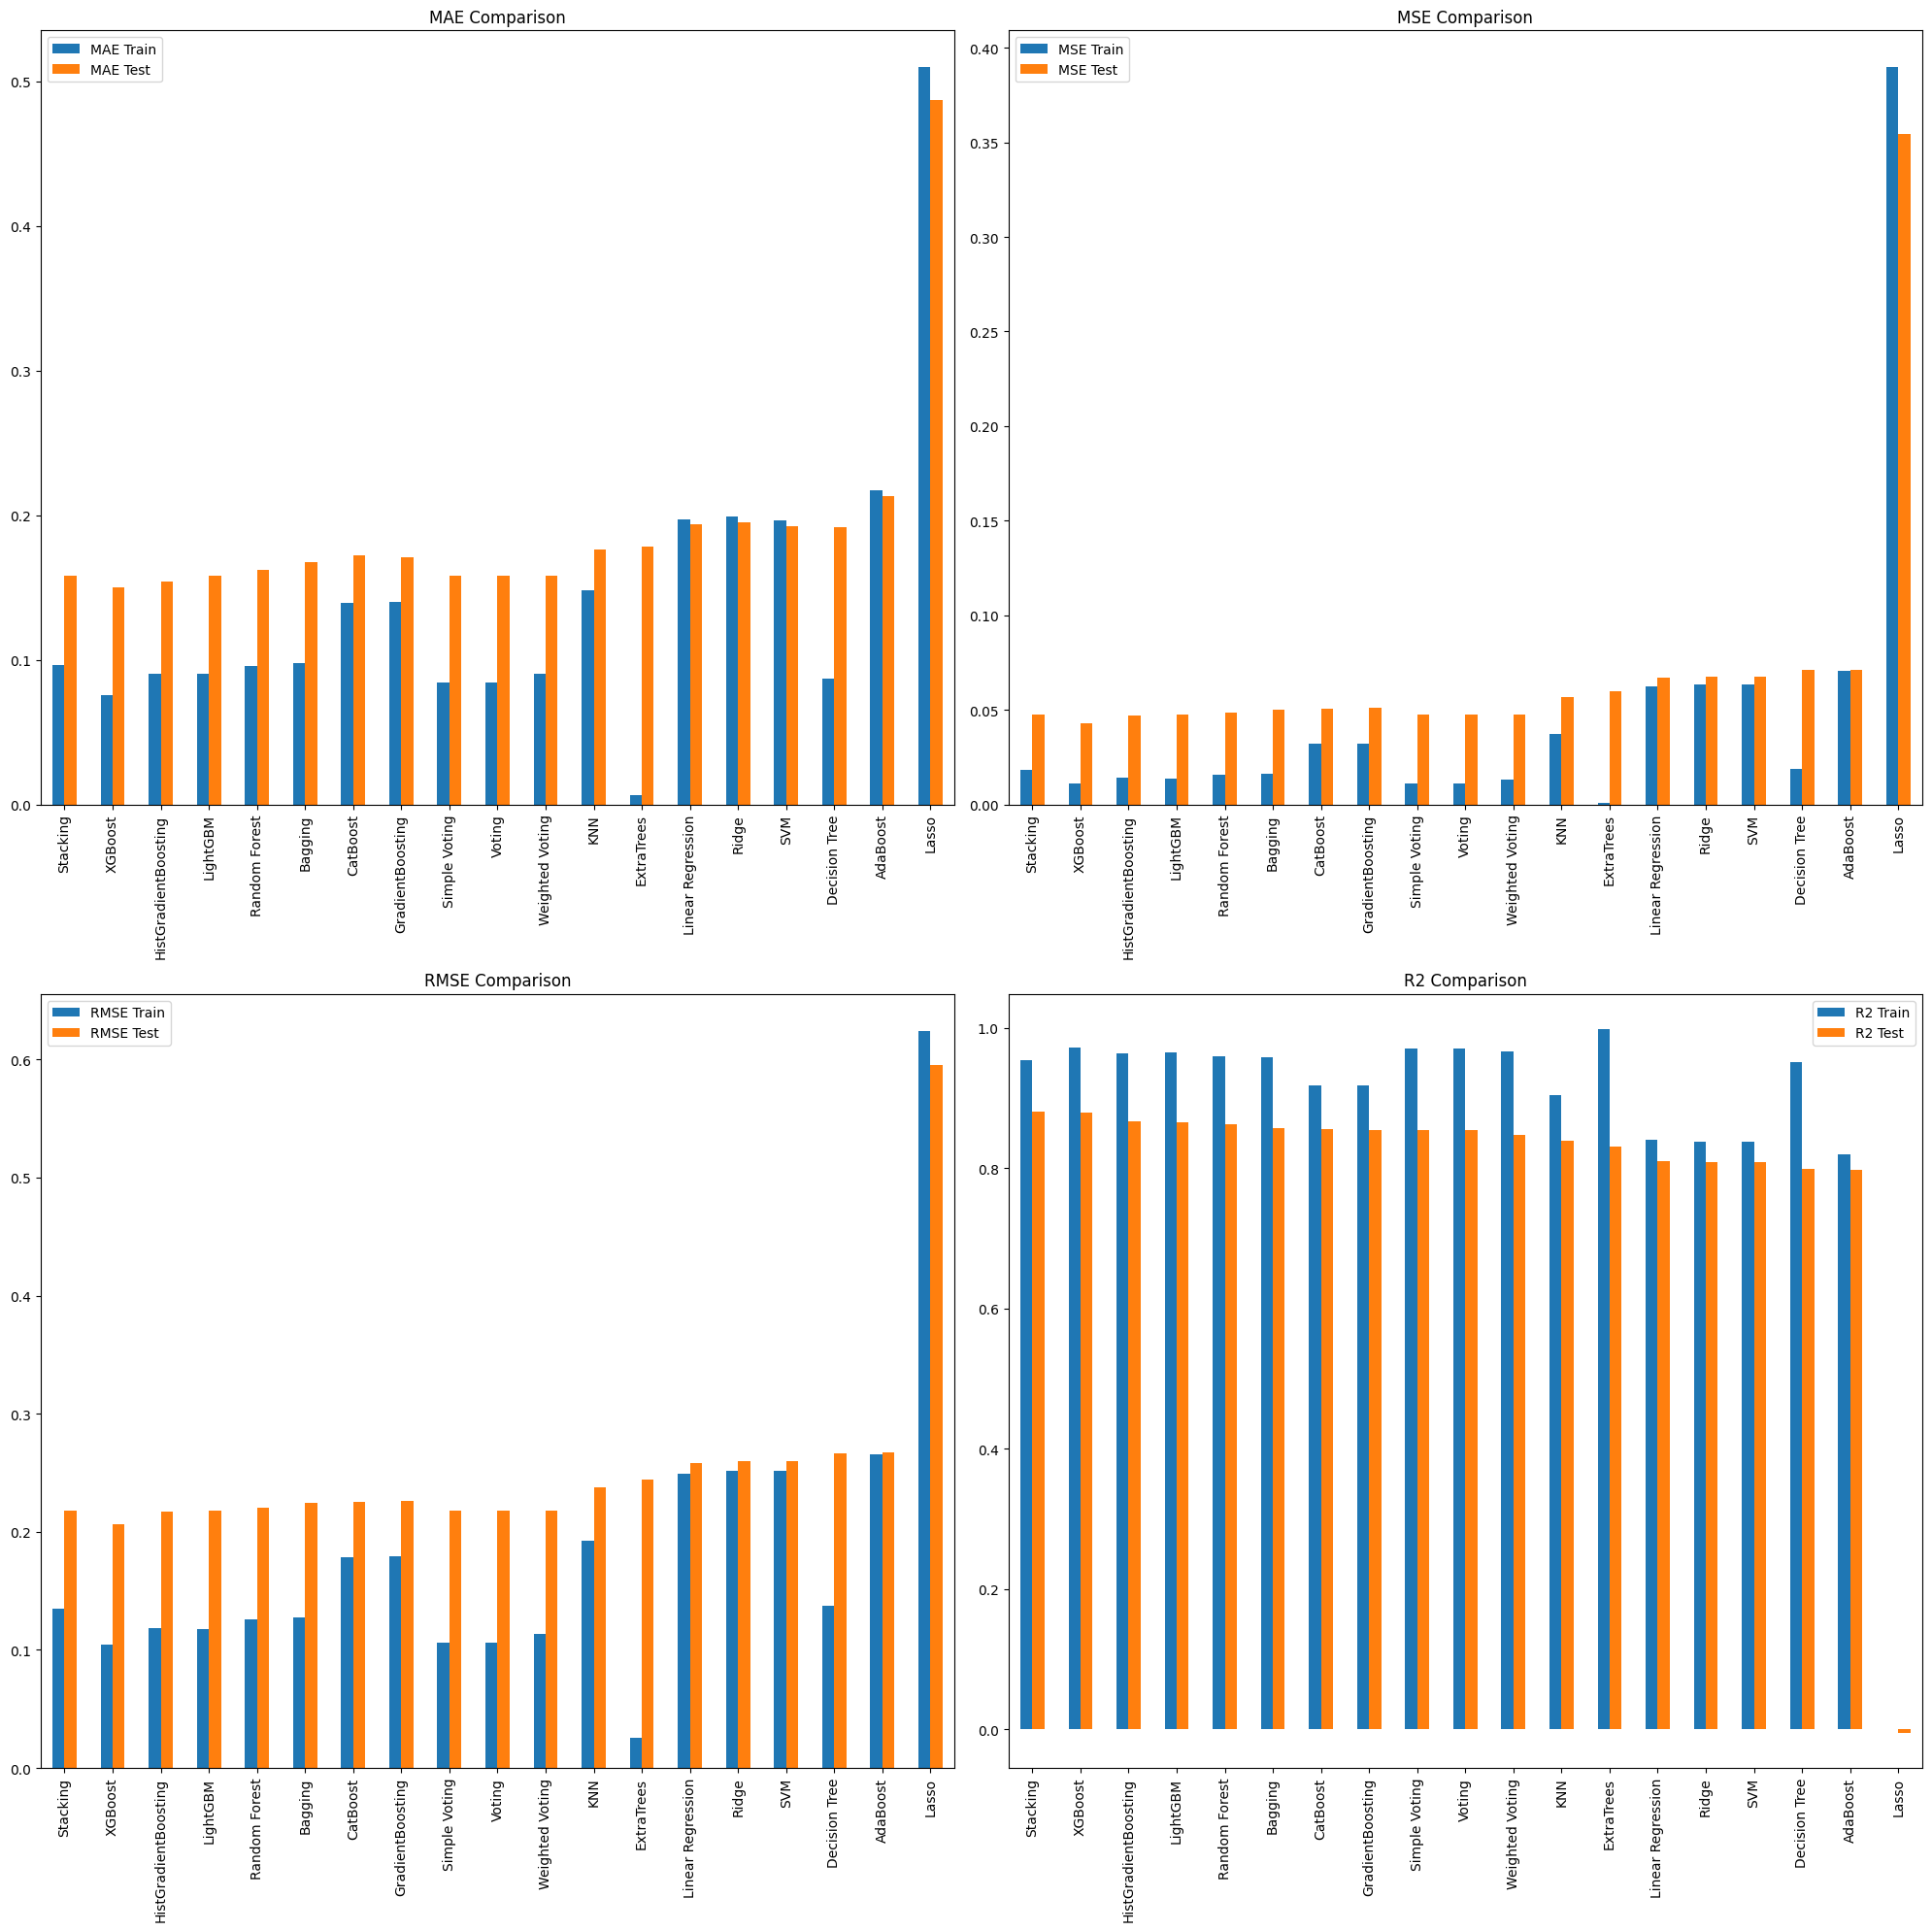

In [48]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [49]:
import gradio as gr

raw_X = df_clean.drop(columns="Price")
median_idx = (df_clean["Price"] - df_clean["Price"].median()).abs().idxmin()
typical_laptop = raw_X.loc[[median_idx]]


def prepare_row(row):
    row = row.copy()
    for col in high_card:
        row[col] = row[col].map(target_means[col]).fillna(y_train.mean())

    # no drop_first here (single row), reindex puts the columns in the training order
    row = pd.get_dummies(row, columns=onehot_cols)
    row = row.reindex(columns=X.columns, fill_value=0).astype(float)

    row[skewed] = np.log1p(row[skewed])
    row[num_cols] = scaler.transform(row[num_cols])
    return row


def predict_price(company, type_name, ram, inches, weight, resolution, touchscreen, ips,
                  cpu_brand_, cpu_ghz, ssd, hdd, gpu_brand_, os_name):
    numbers = [inches, weight, cpu_ghz, ssd, hdd]
    if any(v is None for v in numbers):
        return " "

    x_res, y_res = (int(v) for v in resolution.split("x"))

    row = typical_laptop.copy()
    row["Company"] = company
    row["TypeName"] = type_name
    row["Ram"] = int(ram)
    row["Inches"] = inches
    row["Weight"] = weight
    row["X_res"] = x_res
    row["Y_res"] = y_res
    row["PPI"] = np.sqrt(x_res ** 2 + y_res ** 2) / inches
    row["Touchscreen"] = int(touchscreen)
    row["IPS"] = int(ips)
    row["Cpu_brand"] = cpu_brand_
    row["Cpu_GHz"] = cpu_ghz
    row["SSD"] = ssd
    row["HDD"] = hdd
    row["Hybrid"] = 0
    row["Flash"] = 0
    row["Gpu_brand"] = gpu_brand_
    row["OS"] = os_name

    price = np.expm1(best_model.predict(prepare_row(row)))[0]
    return f"Estimated Price: {price:,.0f}"


demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Dropdown(sorted(df_clean["Company"].unique()), label="Company", value="Dell"),
        gr.Dropdown(sorted(df_clean["TypeName"].unique()), label="Type", value="Notebook"),
        gr.Dropdown([2, 4, 6, 8, 12, 16, 24, 32, 64], label="RAM (GB)", value=8),
        gr.Number(label="Screen Size (inches)", value=15.6),
        gr.Number(label="Weight (kg)", value=2.0),
        gr.Dropdown(["1366x768", "1600x900", "1920x1080", "2560x1440", "2560x1600", "2880x1800",
                     "3200x1800", "3840x2160"], label="Screen Resolution", value="1920x1080"),
        gr.Checkbox(label="Touchscreen", value=False),
        gr.Checkbox(label="IPS Panel", value=False),
        gr.Dropdown(sorted(df_clean["Cpu_brand"].unique()), label="CPU", value="Intel Core i5"),
        gr.Number(label="CPU Speed (GHz)", value=2.5),
        gr.Dropdown([0, 8, 16, 32, 64, 128, 256, 512, 1024, 2048], label="SSD (GB)", value=256),
        gr.Dropdown([0, 500, 1024, 2048], label="HDD (GB)", value=0),
        gr.Dropdown(sorted(df_clean["Gpu_brand"].unique()), label="GPU Brand", value="Intel"),
        gr.Dropdown(sorted(df_clean["OS"].unique()), label="Operating System", value="Windows"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Laptop Price Prediction App",
    description="Enter the main laptop specs to estimate its price. Other details are set to a typical laptop.",
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://754e039fba7508e533.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
